In [1]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_pinball_loss
from datetime import datetime, timedelta

In [2]:
X_train = np.load('../../output/data_eagles_vezhen/qrf/X_train2.npy')
y_train = np.load('../../output/data_eagles_vezhen/qrf/y_train2.npy')
X_test = np.load('../../output/data_eagles_vezhen/qrf/X_test2.npy')
y_test = np.load('../../output/data_eagles_vezhen/qrf/y_test2.npy')
X_val = np.load('../../output/data_eagles_vezhen/qrf/X_val2.npy')
y_val = np.load('../../output/data_eagles_vezhen/qrf/y_val2.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [3]:
def train_and_eval_xgb(X_train, X_test, y_train, y_test, i, feat, best_hyper):
    y_train_tmp = y_train\
        .reshape((-1, 5, 3))\
        [:, i, feat]

    y_test_tmp = y_test\
        .reshape((-1, 5, 3))\
        [:, i, feat]

    model_low_xgb = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )

    model_high_xgb = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )

    model_low_xgb.fit(X_train, y_train_tmp)
    model_high_xgb.fit(X_train, y_train_tmp)

    y_low = model_low_xgb.predict(X_test)
    y_high = model_high_xgb.predict(X_test)

    picp = np.mean(
        (y_low < y_test_tmp) & (y_high > y_test_tmp)
    )
    pinaw = np.mean(
        np.mean( np.abs(y_high - y_low) )
    )
    loss_low = mean_pinball_loss(y_test_tmp, y_low, alpha=0.025)
    loss_high = mean_pinball_loss(y_test_tmp, y_high, alpha=0.975)

    return picp, pinaw, loss_low, loss_high

In [23]:
metrics_xgb = {
    'feature': [],
    'time_step': [],
    'picp': [],
    'pinaw': [],
    'loss_low': [],
    'loss_high': []
}

features = ['delta_cog', 'delta_dif', 'dif']
hyperparams = [
    # Delta COG
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 0.8,
    },
    # Delta DIF
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 0.6,
    },
    # DIF
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 0.8,
    }
]

for feat in range(3):

    best_hyper = hyperparams[feat]

    for i in range(5):

        picp, pinaw, loss_low, loss_high = train_and_eval_xgb(
            X_train, X_test, y_train, y_test, i, feat, best_hyper
        )

        metrics_xgb['feature'].append(features[feat])
        metrics_xgb['time_step'].append(i*5+5)
        metrics_xgb['picp'].append(picp)
        metrics_xgb['pinaw'].append(pinaw)
        metrics_xgb['loss_low'].append(loss_low)
        metrics_xgb['loss_high'].append(loss_high)

In [24]:
pd.DataFrame(metrics_xgb)

,feature,time_step,picp,pinaw,loss_low,loss_high
0,delta_cog,5,0.947723,0.362817,0.005736,0.005894
1,delta_cog,10,0.947043,0.431263,0.006741,0.007070
2,delta_cog,15,0.942004,0.427296,0.006813,0.007139
3,delta_cog,20,0.941880,0.429845,0.006851,0.007133
4,delta_cog,25,0.942437,0.431152,0.006818,0.007115
5,delta_dif,5,0.956101,0.204771,0.002956,0.003050
6,delta_dif,10,0.956410,0.237422,0.003361,0.003553
7,delta_dif,15,0.952484,0.236121,0.003422,0.003587
8,delta_dif,20,0.949454,0.236171,0.003456,0.003656
9,delta_dif,25,0.949918,0.237938,0.003474,0.003685


In [25]:
import quantile_forest as qrf

In [26]:
def train_and_eval_qrf(X_train, X_test, y_train, y_test, best_hyper):

    qrf_model = qrf.RandomForestQuantileRegressor(**best_hyper, n_jobs=-1)
    qrf_model.fit(X_train, y_train)

    y_pred = qrf_model.predict(X_test, quantiles=[0.025, 0.975])
    y_low = y_pred[:, :, 0]
    y_high = y_pred[:, :, 1]

    y_test =  y_test.reshape((-1,5,3))
    y_low = y_low.reshape((-1,5,3))
    y_high = y_high.reshape((-1,5,3))

    picp_res = np.mean( (y_test < y_high) & (y_test > y_low), axis=0 )
    pinaw_res = np.mean( np.abs(y_high - y_low), axis=0 )
    loss_low_res = mean_pinball_loss( y_test.reshape((-1, 15)), y_low.reshape((-1,15)), alpha=0.025, multioutput='raw_values')
    loss_high_res = mean_pinball_loss( y_test.reshape((-1,15)), y_high.reshape((-1,15)), alpha=0.975, multioutput='raw_values')

    loss_low_res = loss_low_res.reshape((5, 3))
    loss_high_res = loss_high_res.reshape((5, 3))

    df_picp = pd.DataFrame(picp_res, columns=['delta_cog', 'delta_dif', 'dif'])
    df_picp['time_step'] = list(range(5,30,5))

    df_pinaw = pd.DataFrame(pinaw_res, columns=['delta_cog', 'delta_dif', 'dif'])
    df_pinaw['time_step'] = list(range(5,30,5))

    df_loss_low = pd.DataFrame(loss_low_res, columns=['delta_cog', 'delta_dif', 'dif'])
    df_loss_low['time_step'] = list(range(5,30,5))

    df_loss_high = pd.DataFrame(loss_high_res, columns=['delta_cog', 'delta_dif', 'dif'])
    df_loss_high['time_step'] = list(range(5,30,5))

    df_picp = df_picp.melt(id_vars='time_step')
    df_picp = df_picp.rename(columns={'value': 'picp'})

    df_pinaw = df_pinaw.melt(id_vars='time_step')
    df_pinaw = df_pinaw.rename(columns={'value': 'pinaw'})

    df_loss_low = df_loss_low.melt(id_vars='time_step')
    df_loss_low = df_loss_low.rename(columns={'value': 'loss_low'})

    df_loss_high = df_loss_high.melt(id_vars='time_step')
    df_loss_high = df_loss_high.rename(columns={'value': 'loss_high'})
    
    metrics_qrf = pd.concat([
        df_picp.set_index(['time_step', 'variable']),
        df_pinaw.set_index(['time_step', 'variable']),
        df_loss_low.set_index(['time_step', 'variable']),
        df_loss_high.set_index(['time_step', 'variable'])
    ], axis=1)

    return metrics_qrf

In [27]:
best_params = {
    'n_estimators': 50,
    'max_depth': 8,
    'max_samples': 1.0,
    'max_features': 0.75,
    'max_samples_leaf': 5,
}
metrics_qrf = train_and_eval_qrf(X_train, X_test, y_train, y_test, best_params)

In [28]:
metrics_qrf

,,picp,pinaw,loss_low,loss_high
time_step,variable,,,,
5,delta_cog,0.954153,0.453337,0.006944,0.007162
10,delta_cog,0.948063,0.463828,0.007410,0.007615
15,delta_cog,0.948187,0.468980,0.007500,0.007776
20,delta_cog,0.944013,0.463373,0.007547,0.007848
25,delta_cog,0.945590,0.467159,0.007499,0.007840
5,delta_dif,0.965561,0.235091,0.003350,0.003456
10,delta_dif,0.959100,0.244378,0.003475,0.003681
15,delta_dif,0.955359,0.242319,0.003533,0.003712
20,delta_dif,0.957307,0.246130,0.003501,0.003795


In [29]:
metrics_xgb_frame = pd.DataFrame(metrics_xgb)
metrics_xgb_frame['model'] = 'XGBoost'
metrics_qrf_frame = metrics_qrf\
    .reset_index()\
    .rename(columns={'variable': 'feature'})\
    [['feature', 'time_step', 'picp', 'pinaw', 'loss_low', 'loss_high']]
metrics_qrf_frame['model'] = 'QRF'

metrics = pd.concat(
    [metrics_xgb_frame, metrics_qrf_frame],
    ignore_index=True
)
metrics

,feature,time_step,picp,pinaw,loss_low,loss_high,model
0,delta_cog,5,0.947723,0.362817,0.005736,0.005894,XGBoost
1,delta_cog,10,0.947043,0.431263,0.006741,0.007070,XGBoost
2,delta_cog,15,0.942004,0.427296,0.006813,0.007139,XGBoost
3,delta_cog,20,0.941880,0.429845,0.006851,0.007133,XGBoost
4,delta_cog,25,0.942437,0.431152,0.006818,0.007115,XGBoost
5,delta_dif,5,0.956101,0.204771,0.002956,0.003050,XGBoost
6,delta_dif,10,0.956410,0.237422,0.003361,0.003553,XGBoost
7,delta_dif,15,0.952484,0.236121,0.003422,0.003587,XGBoost
8,delta_dif,20,0.949454,0.236171,0.003456,0.003656,XGBoost
9,delta_dif,25,0.949918,0.237938,0.003474,0.003685,XGBoost


In [30]:
picp_lstm = pd.read_csv('../../output/data_eagles_vezhen/lstm-ae/picp-lstm.csv')
picp_frame = picp_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

picp_frame = picp_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'picp'
    })\
    .set_index(['time_step', 'feature'])

pinaw_lstm = pd.read_csv('../../output/data_eagles_vezhen/lstm-ae/pinaw-lstm.csv')
pinaw_frame = pinaw_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

pinaw_frame = pinaw_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'pinaw'
    })\
    .set_index(['time_step', 'feature'])

loss_low_lstm = pd.read_csv('../../output/data_eagles_vezhen/lstm-ae/loss_low-lstm.csv')
loss_low_frame = loss_low_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

loss_low_frame = loss_low_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'loss_low'
    })\
    .set_index(['time_step', 'feature'])

loss_high_lstm = pd.read_csv('../../output/data_eagles_vezhen/lstm-ae/loss_high-lstm.csv')
loss_high_frame = loss_high_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

loss_high_frame = loss_high_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'loss_high'
    })\
    .set_index(['time_step', 'feature'])

metrics_lstmae = pd.concat([
    picp_frame,
    pinaw_frame,
    loss_low_frame,
    loss_high_frame
], axis=1)
metrics_lstmae['model'] = 'LSTM-AE'
metrics_lstmae.reset_index(inplace=True)

In [31]:
metrics = pd.concat([metrics, metrics_lstmae], ignore_index=True)

In [32]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

<>:32: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
<>:32: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_9607/3881723727.py:32: SyntaxWarning: invalid escape sequence '\D'
  axs[0].set_title('PICP of $\Delta DIF$ PIs (dataset EV)', size=20)
/tmp/ipykernel_9607/3881723727.py:68: SyntaxWarning: invalid escape sequence '\D'
  axs[1].set_title('PINAW of $\Delta DIF$ PIs (dataset EV)', size=20)


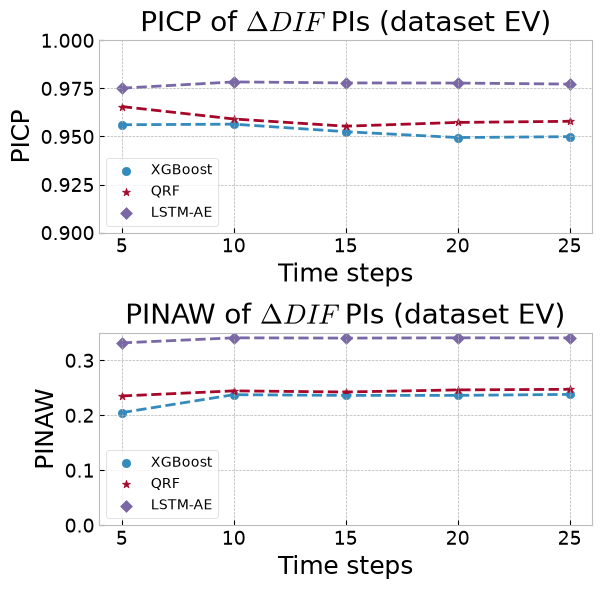

In [33]:
fig, axs = plt.subplots(nrows=2,  figsize=(6,6))

picp_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
picp_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
picp_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[0].plot(picp_xgb['time_step'], picp_xgb['picp'], linestyle='--')
axs[0].plot(picp_qrf['time_step'], picp_qrf['picp'], linestyle='--')
axs[0].plot(picp_lstm['time_step'], picp_lstm['picp'], linestyle='--')

axs[0].scatter(picp_xgb['time_step'], picp_xgb['picp'], label='XGBoost')
axs[0].scatter(picp_qrf['time_step'], picp_qrf['picp'], marker='*', label='QRF')
axs[0].scatter(picp_lstm['time_step'], picp_lstm['picp'], marker='D', label='LSTM-AE')
axs[0].legend()

axs[0].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)

axs[0].set_ylabel('PICP', size=18)
axs[0].set_xlabel('Time steps', size=18)
axs[0].set_title('PICP of $\Delta DIF$ PIs (dataset EV)', size=20)
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_ylim((0.9, 1.0))

# plt.tight_layout()
# plt.savefig('picp-models.png', dpi=750)
pinaw_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
pinaw_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
pinaw_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[1].plot(pinaw_xgb['time_step'], pinaw_xgb['pinaw'], linestyle='--')
axs[1].plot(pinaw_qrf['time_step'], pinaw_qrf['pinaw'], linestyle='--')
axs[1].plot(pinaw_lstm['time_step'], pinaw_lstm['pinaw'], linestyle='--')

axs[1].scatter(pinaw_xgb['time_step'], pinaw_xgb['pinaw'], label='XGBoost')
axs[1].scatter(pinaw_qrf['time_step'], pinaw_qrf['pinaw'], marker='*', label='QRF')
axs[1].scatter(pinaw_lstm['time_step'], pinaw_lstm['pinaw'], marker='D', label='LSTM-AE')
axs[1].legend()

axs[1].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)
axs[1].set_ylim((0, 0.35))

axs[1].set_ylabel('PINAW', size=18)
axs[1].set_xlabel('Time steps', size=18)
axs[1].set_title('PINAW of $\Delta DIF$ PIs (dataset EV)', size=20)
axs[1].tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig('metrics-models-delta-dif.png', dpi=750)

In [34]:
loss_low_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_low_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_low_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

print(
    loss_low_xgb['pinaw'].mean(),
    loss_low_qrf['pinaw'].mean(),
    loss_low_lstm['pinaw'].mean(),
)

0.23048479855060577 0.24302794884277504 0.33894950599999996


In [35]:
loss_low_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_low_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_low_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

print(
    loss_low_xgb['picp'].mean(),
    loss_low_qrf['picp'].mean(),
    loss_low_lstm['picp'].mean(),
)

0.9528735276841749 0.9590441153739141 0.9772786040681781


In [36]:
loss_low_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_low_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_low_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

print(
    loss_low_xgb['loss_low'].mean(),
    loss_low_qrf['loss_low'].mean(),
    loss_low_lstm['loss_low'].mean(),
)

0.0033338564026993015 0.0034769818718050844 0.0044153583589833


In [37]:
loss_high_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_high_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_high_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

print(
    loss_high_xgb['loss_high'].mean(),
    loss_high_qrf['loss_high'].mean(),
    loss_high_lstm['loss_high'].mean(),
)

0.003506423113914385 0.0036942518961243704 0.00474795625335166


<>:32: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
<>:32: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_9607/3459403452.py:32: SyntaxWarning: invalid escape sequence '\D'
  axs[0].set_title('Quantile loss of $\Delta DIF$\nlower bound (dataset EV)', size=20)
/tmp/ipykernel_9607/3459403452.py:68: SyntaxWarning: invalid escape sequence '\D'
  axs[1].set_title('Quantile loss of $\Delta DIF$\nupper bound (dataset EV)', size=20)


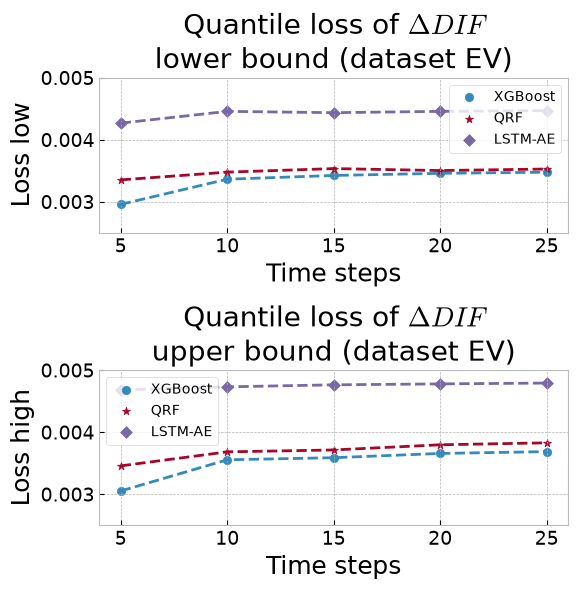

In [38]:
fig, axs = plt.subplots(nrows=2,  figsize=(6,6))

loss_low_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_low_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_low_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[0].plot(loss_low_xgb['time_step'], loss_low_xgb['loss_low'], linestyle='--')
axs[0].plot(loss_low_qrf['time_step'], loss_low_qrf['loss_low'], linestyle='--')
axs[0].plot(loss_low_lstm['time_step'], loss_low_lstm['loss_low'], linestyle='--')

axs[0].scatter(loss_low_xgb['time_step'], loss_low_xgb['loss_low'], label='XGBoost')
axs[0].scatter(loss_low_qrf['time_step'], loss_low_qrf['loss_low'], marker='*', label='QRF')
axs[0].scatter(loss_low_lstm['time_step'], loss_low_lstm['loss_low'], marker='D', label='LSTM-AE')
axs[0].legend()

axs[0].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)

axs[0].set_ylabel('Loss low', size=18)
axs[0].set_xlabel('Time steps', size=18)
axs[0].set_title('Quantile loss of $\Delta DIF$\nlower bound (dataset EV)', size=20)
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_ylim((0.0025, 0.005))

# plt.tight_layout()
# plt.savefig('loss_low-models.png', dpi=750)
loss_high_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
loss_high_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
loss_high_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[1].plot(loss_high_xgb['time_step'], loss_high_xgb['loss_high'], linestyle='--')
axs[1].plot(loss_high_qrf['time_step'], loss_high_qrf['loss_high'], linestyle='--')
axs[1].plot(loss_high_lstm['time_step'], loss_high_lstm['loss_high'], linestyle='--')

axs[1].scatter(loss_high_xgb['time_step'], loss_high_xgb['loss_high'], label='XGBoost')
axs[1].scatter(loss_high_qrf['time_step'], loss_high_qrf['loss_high'], marker='*', label='QRF')
axs[1].scatter(loss_high_lstm['time_step'], loss_high_lstm['loss_high'], marker='D', label='LSTM-AE')
axs[1].legend()

axs[1].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)
axs[1].set_ylim((0.0025, 0.005))

axs[1].set_ylabel('Loss high', size=18)
axs[1].set_xlabel('Time steps', size=18)
axs[1].set_title('Quantile loss of $\Delta DIF$\nupper bound (dataset EV)', size=20)
axs[1].tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig('loss-models-delta-dif.png', dpi=750)

# Yi-peng 3

In [39]:
df_picp_qrf = pd.DataFrame({'delta_cog': {0: 0.9547098649024639, 1: 0.9486196556094847, 2: 0.9455590935790027, 3: 0.9445079914675241, 4: 0.946455621850558}, 'delta_dif': {0: 0.9623767273626611, 1: 0.9578013417009306, 2: 0.9555754784060345, 3: 0.9577085973969766, 4: 0.9554209045661113}, 'dif': {0: 0.9541224843107552, 1: 0.949794416792902, 2: 0.9419729804927814, 3: 0.9360991745756948, 4: 0.9333168454570748}, 'time_step': {0: 5, 1: 10, 2: 15, 3: 20, 4: 25}})
df_pinaw_qrf = pd.DataFrame({'delta_cog': {0: 0.4536330206412251, 1: 0.4705316869736593, 2: 0.47020567486889636, 3: 0.46413086410886656, 4: 0.46307828084244484}, 'delta_dif': {0: 0.23208643984234023, 1: 0.24498019299383347, 2: 0.2437543506571875, 3: 0.24588033127792336, 4: 0.24505288937012273}, 'dif': {0: 0.224733393159696, 1: 0.31477944412224695, 2: 0.4015791409962343, 3: 0.4537566497761681, 4: 0.4839265446093872}, 'time_step': {0: 5, 1: 10, 2: 15, 3: 20, 4: 25}})

In [40]:
X_train = np.load('../../output/data_yipeng3/qrf/X_train.npy')
y_train = np.load('../../output/data_yipeng3/qrf/y_train.npy')
X_test = np.load('../../output/data_yipeng3/qrf/X_test.npy')
y_test = np.load('../../output/data_yipeng3/qrf/y_test.npy')
X_val = np.load('../../output/data_yipeng3/qrf/X_val.npy')
y_val = np.load('../../output/data_yipeng3/qrf/y_val.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [42]:
metrics_xgb = {
    'feature': [],
    'time_step': [],
    'picp': [],
    'pinaw': [],
    'loss_low': [],
    'loss_high': []
}

features = ['delta_cog', 'delta_dif', 'dif']
hyperparams = [
    # Delta COG
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 0.6
    },
    # Delta DIF
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 0.6
    },
    # DIF
    {
        'n_estimators': 128,
        'max_depth': 4,
        'eta': 0.05,
        'subsample': 1.0
    }
]

for feat in range(3):

    best_hyper = hyperparams[feat]

    for i in range(5):

        picp, pinaw, loss_low, loss_high = train_and_eval_xgb(
            X_train, X_test, y_train, y_test, i, feat, best_hyper
        )

        metrics_xgb['feature'].append(features[feat])
        metrics_xgb['time_step'].append(i*5+5)

        metrics_xgb['picp'].append(picp)
        metrics_xgb['pinaw'].append(pinaw)

        metrics_xgb['loss_low'].append(loss_low)
        metrics_xgb['loss_high'].append(loss_high)

In [43]:
df_picp_lstm = pd.read_csv('df_picp_lstm_yipeng.csv')
df_pinaw_lstm = pd.read_csv('df_pinaw_lstm_yipeng.csv')

In [24]:
metrics_qrf = pd.concat([
    df_picp.set_index(['time_step', 'variable']),
    df_pinaw.set_index(['time_step', 'variable'])
], axis=1)

In [29]:
metrics_xgb_frame = pd.DataFrame(metrics_xgb)
metrics_xgb_frame['model'] = 'XGBoost'
metrics_qrf_frame = metrics_qrf\
    .reset_index()\
    .rename(columns={'variable': 'feature'})\
    [['feature', 'time_step', 'picp', 'pinaw']]
metrics_qrf_frame['model'] = 'QRF'

metrics = pd.concat(
    [metrics_xgb_frame, metrics_qrf_frame],
    ignore_index=True
)
metrics

,feature,time_step,picp,pinaw,model
0,delta_cog,5,0.950289,0.367497,XGBoost
1,delta_cog,10,0.946487,0.431123,XGBoost
2,delta_cog,15,0.947074,0.437638,XGBoost
3,delta_cog,20,0.945930,0.436678,XGBoost
4,delta_cog,25,0.944168,0.432698,XGBoost
5,delta_dif,5,0.956101,0.204771,XGBoost
6,delta_dif,10,0.956410,0.237422,XGBoost
7,delta_dif,15,0.952484,0.236121,XGBoost
8,delta_dif,20,0.949454,0.236171,XGBoost
9,delta_dif,25,0.949918,0.237938,XGBoost


In [30]:
picp_frame = df_picp_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

picp_frame = picp_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'picp'
    })\
    .set_index(['time_step', 'feature'])

pinaw_frame = df_pinaw_lstm\
    .drop(columns='Unnamed: 0')\
    .melt(id_vars='time_step')

pinaw_frame = pinaw_frame\
    .rename(columns={
        'variable': 'feature',
        'value': 'pinaw'
    })\
    .set_index(['time_step', 'feature'])

metrics_lstmae = pd.concat([
    picp_frame,
    pinaw_frame
], axis=1)
metrics_lstmae['model'] = 'LSTM-AE'
metrics_lstmae.reset_index(inplace=True)

In [38]:
metrics = pd.concat([metrics, metrics_lstmae], ignore_index=True)

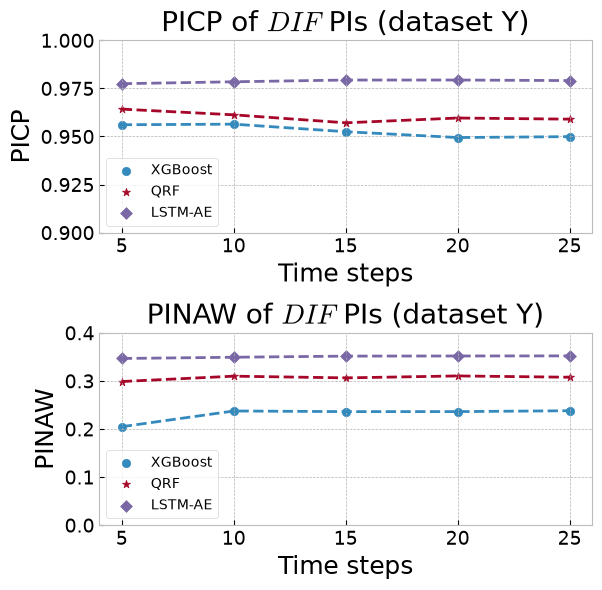

In [40]:
fig, axs = plt.subplots(nrows=2,  figsize=(6,6))

picp_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
picp_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
picp_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[0].plot(picp_xgb['time_step'], picp_xgb['picp'], linestyle='--')
axs[0].plot(picp_qrf['time_step'], picp_qrf['picp'], linestyle='--')
axs[0].plot(picp_lstm['time_step'], picp_lstm['picp'], linestyle='--')

axs[0].scatter(picp_xgb['time_step'], picp_xgb['picp'], label='XGBoost')
axs[0].scatter(picp_qrf['time_step'], picp_qrf['picp'], marker='*', label='QRF')
axs[0].scatter(picp_lstm['time_step'], picp_lstm['picp'], marker='D', label='LSTM-AE')
axs[0].legend()

axs[0].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)

axs[0].set_ylabel('PICP', size=18)
axs[0].set_xlabel('Time steps', size=18)
axs[0].set_title('PICP of $DIF$ PIs (dataset Y)', size=20)
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_ylim((0.9, 1.0))

# plt.tight_layout()
# plt.savefig('picp-models.png', dpi=750)
pinaw_xgb = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'XGBoost')
]
pinaw_qrf = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'QRF')
]
pinaw_lstm = metrics[
    (metrics['feature'] == 'delta_dif') &
    (metrics['model'] == 'LSTM-AE')
]

axs[1].plot(pinaw_xgb['time_step'], pinaw_xgb['pinaw'], linestyle='--')
axs[1].plot(pinaw_qrf['time_step'], pinaw_qrf['pinaw'], linestyle='--')
axs[1].plot(pinaw_lstm['time_step'], pinaw_lstm['pinaw'], linestyle='--')

axs[1].scatter(pinaw_xgb['time_step'], pinaw_xgb['pinaw'], label='XGBoost')
axs[1].scatter(pinaw_qrf['time_step'], pinaw_qrf['pinaw'], marker='*', label='QRF')
axs[1].scatter(pinaw_lstm['time_step'], pinaw_lstm['pinaw'], marker='D', label='LSTM-AE')
axs[1].legend()

axs[1].set_xticks(
    labels=range(5,30,5),
    ticks=range(5,30,5)
)
axs[1].set_ylim((0, 0.4))

axs[1].set_ylabel('PINAW', size=18)
axs[1].set_xlabel('Time steps', size=18)
axs[1].set_title('PINAW of $DIF$ PIs (dataset Y)', size=20)
axs[1].tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig('metrics-models-dif.png', dpi=750)

In [32]:
loss_low_xgb = metrics_xgb_frame[
    (metrics_xgb_frame['feature'] == 'dif')
]
print( loss_low_xgb['loss_low'].mean() )

loss_high_xgb = metrics_xgb_frame[
    (metrics_xgb_frame['feature'] == 'dif')
]
print( loss_high_xgb['loss_high'].mean() )

0.0053871102832637255
0.005974711501860551


In [33]:
metrics_qrf = pd.DataFrame({'picp': {(5, 'delta_cog'): 0.7182737193557363, (10, 'delta_cog'): 0.7051349429622531, (15, 'delta_cog'): 0.7080100163848271, (20, 'delta_cog'): 0.7033109716511577, (25, 'delta_cog'): 0.7008068754443998, (5, 'delta_dif'): 0.7137910779979596, (10, 'delta_dif'): 0.7020125513958018, (15, 'delta_dif'): 0.706804340433425, (20, 'delta_dif'): 0.7011469378922311, (25, 'delta_dif'): 0.7104831978236004, (5, 'dif'): 0.763131047701487, (10, 'dif'): 0.736080625714904, (15, 'dif'): 0.714316629053699, (20, 'dif'): 0.7033109716511577, (25, 'dif'): 0.6924289733205552}, 'pinaw': {(5, 'delta_cog'): 0.26485034763740434, (10, 'delta_cog'): 0.28500658432619347, (15, 'delta_cog'): 0.28707719469917037, (20, 'delta_cog'): 0.28700699433067417, (25, 'delta_cog'): 0.2834903060403273, (5, 'delta_dif'): 0.14367750855876849, (10, 'delta_dif'): 0.15267171074065433, (15, 'delta_dif'): 0.1537092890670849, (20, 'delta_dif'): 0.15307523301104498, (25, 'delta_dif'): 0.15725034103779117, (5, 'dif'): 0.11680914190292072, (10, 'dif'): 0.17056002456002733, (15, 'dif'): 0.22570189967789697, (20, 'dif'): 0.2675731800045341, (25, 'dif'): 0.2988503192176522}, 'loss_low': {(5, 'delta_cog'): 0.012852315441949515, (10, 'delta_cog'): 0.014634345206831113, (15, 'delta_cog'): 0.015034248258483839, (20, 'delta_cog'): 0.015102144940134583, (25, 'delta_cog'): 0.015099587311023944, (5, 'delta_dif'): 0.006216591107898313, (10, 'delta_dif'): 0.006817041108961424, (15, 'delta_dif'): 0.006909537680244418, (20, 'delta_dif'): 0.007031858752085232, (25, 'delta_dif'): 0.006834245822641602, (5, 'dif'): 0.0049721960502423605, (10, 'dif'): 0.007794514653873276, (15, 'dif'): 0.010772698905662837, (20, 'dif'): 0.012408537187901008, (25, 'dif'): 0.013608919639000842}, 'loss_high': {(5, 'delta_cog'): 0.012689385843357175, (10, 'delta_cog'): 0.014102074565564329, (15, 'delta_cog'): 0.014324575354445748, (20, 'delta_cog'): 0.014635342289364852, (25, 'delta_cog'): 0.014596392463712573, (5, 'delta_dif'): 0.007213204693458832, (10, 'delta_dif'): 0.008184454102019702, (15, 'delta_dif'): 0.008218429144364608, (20, 'delta_dif'): 0.008340708787767572, (25, 'delta_dif'): 0.008108842077474962, (5, 'dif'): 0.0055224880598559066, (10, 'dif'): 0.008195340707868466, (15, 'dif'): 0.010660309208179272, (20, 'dif'): 0.01223718593420762, (25, 'dif'): 0.013633613049339088}})
metrics_qrf.reset_index(inplace=True)
metrics_qrf.columns = ['time_step', 'target', 'picp', 'pinaw', 'loss_low', 'loss_high']

loss_low_qrf = metrics_qrf_frame[
    (metrics_qrf_frame['feature'] == 'dif')
]
print( loss_low_qrf['loss_low'].mean() )

loss_high_qrf = metrics_qrf_frame[
    (metrics_qrf_frame['feature'] == 'dif')
]
print( loss_high_qrf['loss_high'].mean() )

0.005705848041749298
0.006186851776333898


In [35]:
# from lstm-hyper-anomaly-validation-yipeng3
loss_low = [0.008568, 0.008715, 0.008786, 0.008838, 0.008881]
loss_high = [0.006583, 0.007122, 0.007280, 0.007386, 0.007481]

print(np.mean(loss_low))
print(np.mean(loss_high))

0.0087576
0.0071704


In [34]:
loss_low_lstm = pd.read_csv('../../output/data_yipeng3/lstm-ae/loss_low-lstm.csv')
loss_high_lstm = pd.read_csv('../../output/data_yipeng3/lstm-ae/loss_high-lstm.csv')

FileNotFoundError: [Errno 2] No such file or directory: '../../output/data_yipeng3/lstm-ae/loss_low-lstm.csv'